# Guided Order Exploration — Global Food Delivery Market 2026
_Tickets, delivery time, and ratings across 12 cities and three order channels_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [luthfimuthathohirin/global-food-delivery-restaurant-market-2026](https://www.kaggle.com/datasets/luthfimuthathohirin/global-food-delivery-restaurant-market-2026)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Channel, Weather, and the Clock](#Channel)** <br>
**5. [Cuisine, City, and the Ticket](#Cuisine)** <br>
**6. [What Lines Up with the Rating](#Model)** <br>
**7. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one restaurant order in a 2026 market table: 8,000 orders, 12 cities, 7 cuisines, 3 channels, and no blank cells. `order_id` is unique. `cot_market_dynamics_rationale` is also unique, one note per order, so it stays a note.

Dine-in and takeaway record delivery time 0 and delivery fee 0. Those zeros are the channel. Online delivery is the only channel with a positive delivery time (8 to 75 minutes). The rating question below is fit on online orders, where time and fee are delivery measurements.

`customer_satisfaction_tier` is a bin of `customer_rating`: Delighted is 5, Satisfied is 4–4.5, Neutral is 3–3.5, and Dissatisfied is 1–2.5. The rating model uses time, fee, ticket, and weather. The tier stays a label.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

/Users/nicapotato/Documents/repo/project/KaggleNotebooks/eda/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` ranks associations; `sklearn` fits one linear model on a hold-out split (`random_state=7`). `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
KAGGLE_SLUG = "luthfimuthathohirin/global-food-delivery-restaurant-market-2026"
CSV_NAME = "global_food_delivery_enriched_market_2026.csv"


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    path = Path(kagglehub.dataset_download(slug))
    found = path / basename
    assert found.exists(), f"expected {basename} under {path}"
    return found


csv_path = resolve_file(CSV_NAME)
df = pd.read_csv(csv_path)
print("CSV:", csv_path)
print("Dataframe Dimension:", df.shape[0], "Rows,", df.shape[1], "Columns")
assert df.shape == (8000, 26)
assert df.order_id.nunique() == 8000
assert df.cot_market_dynamics_rationale.nunique() == 8000
assert int(df.isna().sum().sum()) == 0
print("Cities:", df.metro_city.nunique(), "| Cuisines:", df.cuisine_category.nunique())
print(df.dtypes.to_string())
display(df.sample(5, random_state=7))

offline = df.order_channel.isin(["Dine-In POS", "Takeaway / Pickup"])
online = df.loc[df.order_channel.eq("Online Delivery App")].copy()
assert df.loc[offline, "actual_delivery_time_min"].eq(0).all()
assert df.loc[offline, "delivery_fee_usd"].eq(0).all()
assert online.actual_delivery_time_min.gt(0).all()
assert len(online) == 5255
print("Online orders:", len(online))

tier_bounds = {
    "Delighted-5Star": (5.0, 5.0, 2349),
    "Satisfied-4Star": (4.0, 4.5, 4071),
    "Neutral-Tolerant-3Star": (3.0, 3.5, 1406),
    "Dissatisfied-ChurRisk-1to2Star": (1.0, 2.5, 174),
}
for tier, (lo, hi, n) in tier_bounds.items():
    stars = df.loc[df.customer_satisfaction_tier.eq(tier), "customer_rating"]
    assert len(stars) == n
    assert stars.min() == lo and stars.max() == hi
print("Satisfaction tier partitions the star rating.")

Dataframe Dimension: 8000 Rows, 26 Columns
Cities: 12 | Cuisines: 7
order_id                                   str
metro_city                                 str
cuisine_category                           str
order_channel                              str
order_value_usd                        float64
discount_applied_usd                   float64
delivery_distance_km                   float64
estimated_prep_time_min                  int64
actual_delivery_time_min               float64
delivery_fee_usd                       float64
customer_rating                        float64
restaurant_price_tier                      str
is_peak_hour                              bool
weather_condition                          str
net_effective_order_price              float64
discount_percentage                    float64
delivery_speed_km_per_hr               float64
total_fulfillment_time_min             float64
delivery_fee_ratio                     float64
customer_spending_tier                 

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,restaurant_price_tier,is_peak_hour,weather_condition,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
3641,ord_1723b4d754aa,New York,Mexican & Tacos,Online Delivery App,111.90,35.00,8.8,21,23.0,5.76,4.5,$$$ Premium / Fine Dining,False,Clear,82.66,31.28,22.96,44.0,0.0515,Occasional-Promo-Seeker,1.66,39.90,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_1723b4d754aa' di metropolis 'New ...,0.989
5086,ord_2e415df774e8,Seoul,Indonesian & Asian Street Food,Online Delivery App,6.31,1.09,5.6,22,19.9,5.18,5.0,$ Budget,False,Rainy,10.40,17.27,16.88,41.9,0.8209,Budget-Saver,3.37,0.83,Delighted-5Star,Overpriced-Delivery-Fee,Pesanan 'ord_2e415df774e8' di metropolis 'Seou...,0.989
1657,ord_062836674d9a,London,Indian & Curries,Takeaway / Pickup,64.14,12.57,0.0,20,0.0,0.00,4.5,$$ Moderate,False,Cloudy / Fog,51.57,19.60,0.00,20.0,0.0000,High-Roller-Gourmet,0.80,25.74,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_062836674d9a' di metropolis 'Lond...,0.989
6842,ord_2d302537b372,Tokyo,Healthy & Bowls,Dine-In POS,14.85,0.00,0.0,30,0.0,0.00,5.0,$ Budget,True,Clear,14.85,0.00,0.00,30.0,0.0000,Budget-Saver,2.30,6.68,Delighted-5Star,Quality-Food-Packaging,Pesanan 'ord_2d302537b372' di metropolis 'Toky...,0.989
788,ord_502ef1759e35,Jakarta,Healthy & Bowls,Online Delivery App,3.82,0.00,7.0,14,15.7,4.95,3.5,$ Budget,False,Clear,8.77,0.00,26.75,29.7,1.2958,Budget-Saver,1.26,-0.09,Neutral-Tolerant-3Star,Overpriced-Delivery-Fee,Pesanan 'ord_502ef1759e35' di metropolis 'Jaka...,0.987


Online orders: 5255
Satisfaction tier partitions the star rating.


**Code Explanation and Reasoning:** <br>
The asserts lock three structural facts. Every order id and every rationale note appears once. Dine-in and takeaway contribute the zero times and zero fees, and every online order has a positive time. The satisfaction tier's min and max are the star bins, so the tier is the rating written as a label.

# **3. Univariate Distributions:** <a id="Univariate"></a>

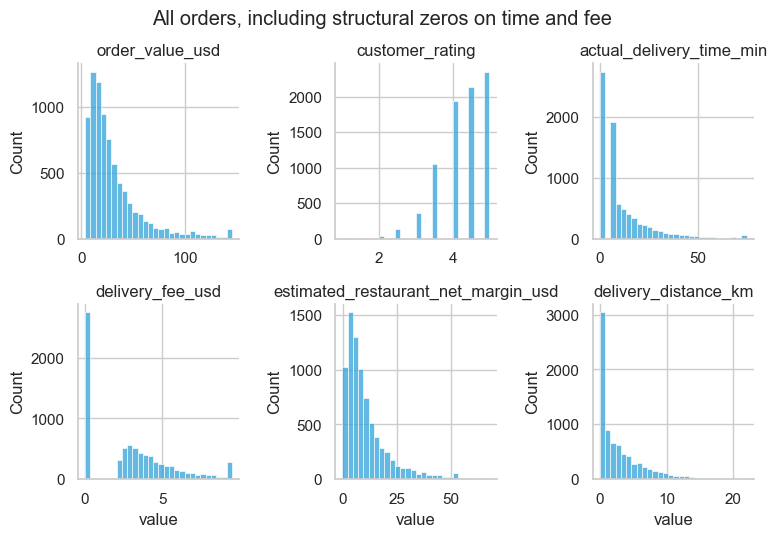

       order_value_usd  customer_rating  estimated_restaurant_net_margin_usd
count          8000.00          8000.00                              8000.00
mean             30.22             4.28                                10.79
std              26.37             0.65                                10.67
min               3.50             1.00                                -0.21
25%              12.92             4.00                                 3.73
50%              21.70             4.50                                 7.44
75%              37.89             5.00                                13.91
max             145.00             5.00                                67.85
order_channel
Online Delivery App    5255
Dine-In POS            1577
Takeaway / Pickup      1168
metro_city
New York     1010
Tokyo         914
Jakarta       824
London        807
Singapore     676
Paris         603
Sydney        575
Berlin        574
Sao Paulo     558
Seoul         502
Mumbai        493


In [3]:
value_cols = [
    "order_value_usd",
    "customer_rating",
    "actual_delivery_time_min",
    "delivery_fee_usd",
    "estimated_restaurant_net_margin_usd",
    "delivery_distance_km",
]
long = df.melt(value_vars=value_cols, var_name="feature", value_name="value")
g = sns.FacetGrid(long, col="feature", col_wrap=3, sharex=False, sharey=False, height=2.6)
g.map_dataframe(sns.histplot, x="value", bins=28, color=PALETTE[0])
g.set_titles("{col_name}")
g.fig.suptitle("All orders, including structural zeros on time and fee", y=1.03)
plt.show()
print(df[["order_value_usd", "customer_rating", "estimated_restaurant_net_margin_usd"]].describe().round(2).to_string())
print(df.order_channel.value_counts().to_string())
print(df.metro_city.value_counts().to_string())
print(df.cuisine_category.value_counts().to_string())

**Interpretation:** <br>
The ticket is right-skewed: median order value is about $21.70 and the mean is about $30. The rating median is 4.5 and the mean is about 4.28. The spike at 0 on delivery time and delivery fee is dine-in and takeaway, 2,745 orders together, against 5,255 online orders. New York is the largest city in the file and burgers are the largest cuisine. Margin can be slightly negative; its median is a few dollars.

# **4. Channel, Weather, and the Clock:** <a id="Channel"></a>

,order_value_usd,actual_delivery_time_min,delivery_fee_usd,customer_rating
order_channel,,,,
Dine-In POS,21.770000,0.000000,0.000000,4.500000
Online Delivery App,21.410000,11.600000,3.940000,4.500000
Takeaway / Pickup,22.490000,0.000000,0.000000,4.500000


,customer_rating,actual_delivery_time_min,delivery_fee_usd,order_value_usd
weather_condition,,,,
Cloudy / Fog,4.500000,10.200000,3.550000,21.480000
Clear,4.500000,10.500000,3.690000,21.740000
Rainy,4.500000,12.900000,4.370000,20.310000
Heavy Rain / Storm,4.000000,17.400000,5.170000,23.840000


,customer_rating,actual_delivery_time_min,delivery_fee_usd,order_value_usd
is_peak_hour,,,,
False,4.500000,9.900000,3.600000,21.300000
True,4.000000,14.000000,4.390000,21.550000


Online orders by peak hour:
is_peak_hour
False    3114
True     2141


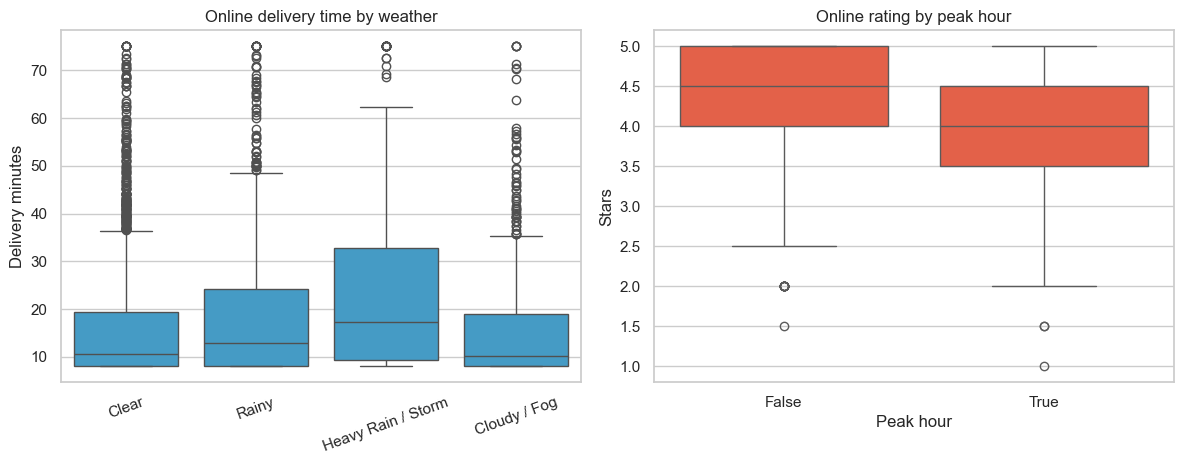

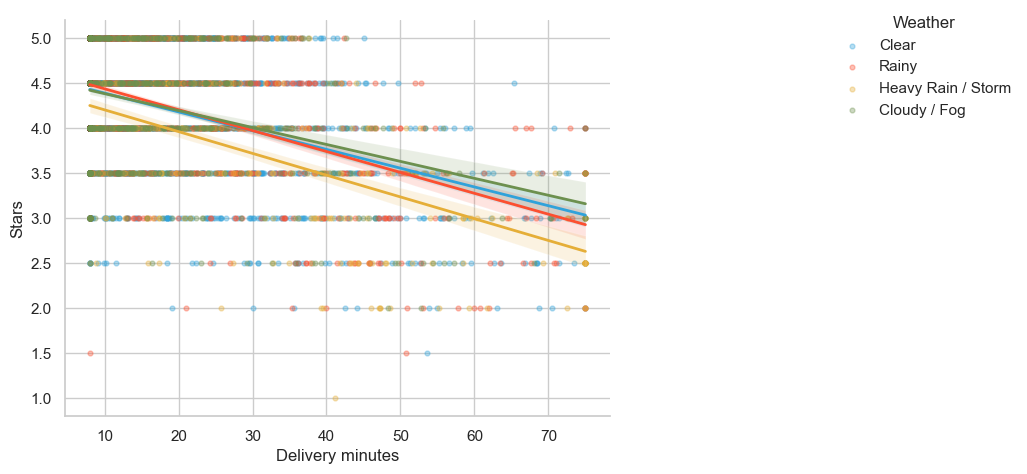

In [4]:
channel = df.groupby("order_channel")[["order_value_usd", "actual_delivery_time_min", "delivery_fee_usd", "customer_rating"]].median()
display(channel.round(2).style.background_gradient(cmap="Blues"))

online_weather = online.groupby("weather_condition")[
    ["customer_rating", "actual_delivery_time_min", "delivery_fee_usd", "order_value_usd"]
].median().sort_values("actual_delivery_time_min")
display(online_weather.round(2).style.background_gradient(cmap="Blues"))

online_peak = online.groupby("is_peak_hour")[
    ["customer_rating", "actual_delivery_time_min", "delivery_fee_usd", "order_value_usd"]
].median()
display(online_peak.round(2).style.background_gradient(cmap="Blues"))
print("Online orders by peak hour:")
print(online.groupby("is_peak_hour").size().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.boxplot(data=online, x="weather_condition", y="actual_delivery_time_min", ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("")
axes[0].set_ylabel("Delivery minutes")
axes[0].set_title("Online delivery time by weather")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=online, x="is_peak_hour", y="customer_rating", ax=axes[1], color=PALETTE[1])
axes[1].set_xlabel("Peak hour")
axes[1].set_ylabel("Stars")
axes[1].set_title("Online rating by peak hour")
fig.tight_layout()
plt.show()

g = sns.lmplot(
    data=online,
    x="actual_delivery_time_min",
    y="customer_rating",
    hue="weather_condition",
    height=4.8,
    aspect=1.35,
    scatter_kws={"s": 12, "alpha": 0.35},
    line_kws={"lw": 2},
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Weather", frameon=False)
g.set_axis_labels("Delivery minutes", "Stars")
plt.show()

**Interpretation:** <br>
On online orders, heavy rain has median delivery time 17.4 minutes, fee $5.17, and rating 4.0. Clear weather has 10.5 minutes, $3.69, and rating 4.5. Peak hour on the same channel has median time 14.0 minutes, fee $4.39, and rating 4.0, against 9.9 minutes, $3.60, and 4.5 off peak. The ticket barely moves. Across all channels the peak-hour time median looks flat, because dine-in and takeaway zeros sit in both groups. The rating line is fit on online orders, where a minute is a minute of delivery.

# **5. Cuisine, City, and the Ticket:** <a id="Cuisine"></a>

,order_value_usd,customer_rating,estimated_restaurant_net_margin_usd
cuisine_category,,,
Healthy & Bowls,20.940000,4.500000,7.220000
Italian & Pizza,21.030000,4.500000,7.180000
Indian & Curries,21.590000,4.500000,7.360000
Burgers & Fast Food,21.640000,4.500000,7.440000
Mexican & Tacos,21.690000,4.500000,7.440000
Indonesian & Asian Street Food,21.880000,4.500000,7.320000
Japanese & Sushi,23.160000,4.500000,8.080000


,order_value_usd,customer_rating
metro_city,,
Sao Paulo,20.590000,4.500000
New York,21.120000,4.500000
Seoul,21.180000,4.500000
Berlin,21.340000,4.500000
Jakarta,21.620000,4.500000
Paris,21.860000,4.500000
Mumbai,21.940000,4.500000
Singapore,21.940000,4.500000
Sydney,22.000000,4.500000


Spearman margin vs order value, all orders: 0.980 (p=0.000e+00)
Spearman rating vs delivery minutes, online: -0.255 (p=1.216e-78)
Spearman rating vs delivery fee, online: -0.243 (p=1.465e-71)


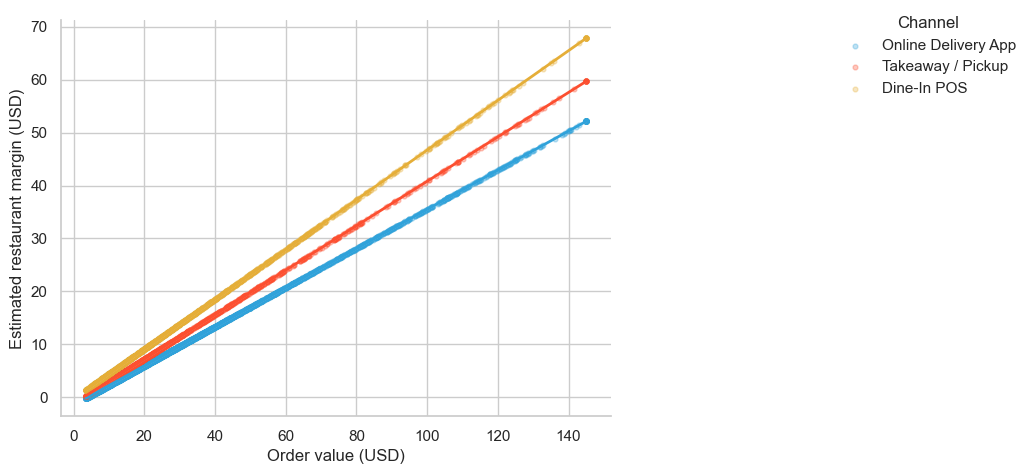

primary_satisfaction_driver
Rapid-Fulfillment          3184
High-Value-Discounting     2100
Quality-Food-Packaging     1272
Overpriced-Delivery-Fee    1198
Weather-Induced-Delay       246


In [5]:
cuisine = df.groupby("cuisine_category")[["order_value_usd", "customer_rating", "estimated_restaurant_net_margin_usd"]].median().sort_values("order_value_usd")
display(cuisine.round(2).style.background_gradient(cmap="Blues"))
city = df.groupby("metro_city")[["order_value_usd", "customer_rating"]].median().sort_values("order_value_usd")
display(city.round(2).style.background_gradient(cmap="Blues"))

rho_margin, p_margin = stats.spearmanr(df.estimated_restaurant_net_margin_usd, df.order_value_usd)
rho_time, p_time = stats.spearmanr(online.customer_rating, online.actual_delivery_time_min)
rho_fee, p_fee = stats.spearmanr(online.customer_rating, online.delivery_fee_usd)
print(f"Spearman margin vs order value, all orders: {rho_margin:.3f} (p={p_margin:.3e})")
print(f"Spearman rating vs delivery minutes, online: {rho_time:.3f} (p={p_time:.3e})")
print(f"Spearman rating vs delivery fee, online: {rho_fee:.3f} (p={p_fee:.3e})")

g = sns.lmplot(
    data=df,
    x="order_value_usd",
    y="estimated_restaurant_net_margin_usd",
    hue="order_channel",
    height=4.8,
    aspect=1.35,
    scatter_kws={"s": 12, "alpha": 0.3},
    line_kws={"lw": 2},
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Channel", frameon=False)
g.set_axis_labels("Order value (USD)", "Estimated restaurant margin (USD)")
plt.show()
print(df.primary_satisfaction_driver.value_counts().to_string())

**Interpretation:** <br>
Every cuisine has a median rating of 4.5. Median tickets sit between $20.94 and $23.16. City medians are similarly close. Cuisine and city are not where this table separates the check or the stars.

Margin tracks the ticket (Spearman 0.980). On online orders, a slower drop and a higher fee go with a lower rating (Spearman −0.255 for minutes, −0.243 for the fee). The satisfaction-driver counts are labels on the order; Rapid-Fulfillment is the largest. They stay out of the rating model, as does the satisfaction tier, which restates the stars.

# **6. What Lines Up with the Rating:** <a id="Model"></a>

In [6]:
y = online.customer_rating
X = online[["actual_delivery_time_min", "delivery_fee_usd", "order_value_usd", "weather_condition"]]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)

time_model = LinearRegression().fit(Xtr[["actual_delivery_time_min"]], ytr)
time_hat = time_model.predict(Xte[["actual_delivery_time_min"]])
print("Online orders in the fit:", len(online))
print("Hold-out R2, rating ~ minutes:", round(r2_score(yte, time_hat), 3))
print("Stars per extra minute:", round(time_model.coef_[0], 4))

three = ["actual_delivery_time_min", "delivery_fee_usd", "order_value_usd"]
three_model = LinearRegression().fit(Xtr[three], ytr)
print("Hold-out R2, rating ~ minutes + fee + ticket:", round(r2_score(yte, three_model.predict(Xte[three])), 3))

pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", three),
        ("cat", OneHotEncoder(drop="first"), ["weather_condition"]),
    ])),
    ("lr", LinearRegression()),
])
pipe.fit(Xtr, ytr)
print("Hold-out R2, those plus weather:", round(r2_score(yte, pipe.predict(Xte)), 3))
print("Reference weather (dropped level):", sorted(online.weather_condition.unique())[0])
names = pipe.named_steps["pre"].get_feature_names_out()
for name, coef in zip(names, pipe.named_steps["lr"].coef_):
    print(f"{name:48s} {coef:8.4f}")

Online orders in the fit: 5255
Hold-out R2, rating ~ minutes: 0.173
Stars per extra minute: -0.0228
Hold-out R2, rating ~ minutes + fee + ticket: 0.176
Hold-out R2, those plus weather: 0.178
Reference weather (dropped level): Clear
num__actual_delivery_time_min                     -0.0308
num__delivery_fee_usd                              0.0638
num__order_value_usd                              -0.0002
cat__weather_condition_Cloudy / Fog               -0.0211
cat__weather_condition_Heavy Rain / Storm         -0.2657
cat__weather_condition_Rainy                       0.0219


**Interpretation:** <br>
On the 5,255 online orders, delivery minutes have hold-out R² 0.173 and a slope of about −0.023 stars per extra minute. Adding fee and ticket reaches 0.176. Adding weather reaches 0.178. The dropped weather level is Clear. Most of the star rating is outside these columns. The gain from fee, ticket, and weather, once minutes are in the model, is small, which matches the medians: heavy rain and peak hour already show up as extra minutes and a one-step drop in the median star (4.5 to 4.0).

# **7. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
These 8,000 orders separate on the delivery, and they do it on the online channel. Dine-in and takeaway record time 0 and fee 0. Online heavy rain runs a median of 17.4 minutes and a $5.17 fee with a median rating of 4.0; clear weather runs 10.5 minutes, $3.69, and 4.5 stars. Online peak hour looks like the same step: 14.0 minutes, $4.39, rating 4.0, against 9.9 minutes and 4.5 stars off peak.

Cuisine median tickets sit between $20.94 and $23.16, and every cuisine has a median rating of 4.5. Margin moves with the ticket (Spearman 0.980). A hold-out line of online rating on minutes has R² 0.173. Fee, ticket, and weather lift that to 0.178. The satisfaction tier is the star rating in bins. The rationale column is one unique note per order.

**Open follow-ups:** <br>
- A restaurant identifier would show whether the slow drops cluster in a few kitchens. This file is one row per order.
- The unique rationale note can be read as text. It has no repeated level to group on.